In [1]:
!pip install pandas numpy matplotlib seaborn requests scipy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import json

print("Day 2 Research Environment Ready!")

Day 2 Research Environment Ready!


In [3]:
biomarkers = {
    "Gene": [
        "ESR1", "PGR", "ERBB2",
        "MKI67", "BRCA1", "BRCA2",
        "PARP1", "CDK4", "CDK6"
    ],

    "Biomarker": [
        "ER", "PR", "HER2",
        "Ki-67", "BRCA1", "BRCA2",
        "PARP1", "CDK4", "CDK6"
    ],

    "Function": [
        "Estrogen signalling",
        "Progesterone signalling",
        "Cell growth signalling",
        "Cell proliferation",
        "DNA repair",
        "DNA repair",
        "DNA repair",
        "Cell cycle regulation",
        "Cell cycle regulation"
    ],

    "Research_Area": [
        "Hormone therapy research",
        "Hormone signalling",
        "HER2 targeted research",
        "Proliferation research",
        "DNA repair research",
        "DNA repair research",
        "DNA repair research",
        "CDK inhibitor research",
        "CDK inhibitor research"
    ]
}

bio_df = pd.DataFrame(biomarkers)

display(bio_df)

,Gene,Biomarker,Function,Research_Area
0,ESR1,ER,Estrogen signalling,Hormone therapy research
1,PGR,PR,Progesterone signalling,Hormone signalling
2,ERBB2,HER2,Cell growth signalling,HER2 targeted research
3,MKI67,Ki-67,Cell proliferation,Proliferation research
4,BRCA1,BRCA1,DNA repair,DNA repair research
5,BRCA2,BRCA2,DNA repair,DNA repair research
6,PARP1,PARP1,DNA repair,DNA repair research
7,CDK4,CDK4,Cell cycle regulation,CDK inhibitor research
8,CDK6,CDK6,Cell cycle regulation,CDK inhibitor research


Research_Area
DNA repair research         3
CDK inhibitor research      2
Hormone signalling          1
Hormone therapy research    1
Proliferation research      1
HER2 targeted research      1
Name: count, dtype: int64


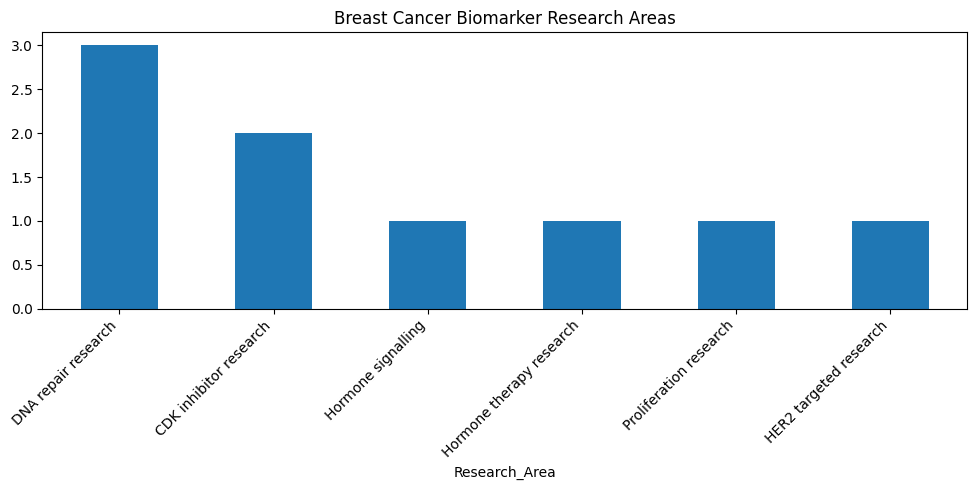

In [4]:
area_counts = bio_df["Research_Area"].value_counts()

print(area_counts)

area_counts.plot(
    kind="bar",
    figsize=(10,5),
    title="Breast Cancer Biomarker Research Areas"
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [5]:
bio_df.to_csv(
    "Day02_Project01_Biomarker_Database.csv",
    index=False
)

print("Project 1 CSV saved!")

Project 1 CSV saved!


In [6]:
import requests
import pandas as pd
import time

genes = [
    "ESR1",
    "PGR",
    "ERBB2",
    "MKI67",
    "BRCA1",
    "BRCA2",
    "PARP1",
    "CDK4",
    "CDK6"
]

records = []

for gene in genes:

    url = "https://rest.uniprot.org/uniprotkb/search"

    params = {
        "query": f"(gene_exact:{gene}) AND (organism_id:9606)",
        "format": "tsv",
        "fields": "accession,protein_name,gene_names,organism_name",
        "size": 1
    }

    response = requests.get(
        url,
        params=params,
        timeout=30
    )

    response.raise_for_status()

    lines = response.text.strip().split("\n")

    if len(lines) > 1:

        values = lines[1].split("\t")

        records.append({
            "Search_Gene": gene,
            "UniProt_ID": values[0],
            "Protein_Name": values[1],
            "Gene_Names": values[2],
            "Organism": values[3]
        })

    else:

        records.append({
            "Search_Gene": gene,
            "UniProt_ID": None,
            "Protein_Name": None,
            "Gene_Names": None,
            "Organism": None
        })

    time.sleep(0.2)

protein_df = pd.DataFrame(records)

display(protein_df)

,Search_Gene,UniProt_ID,Protein_Name,Gene_Names,Organism
0,ESR1,B5TKC0,Estrogen receptor (ER-alpha) (Estradiol recept...,ESR1,Homo sapiens (Human)
1,PGR,P06401,Progesterone receptor (PR) (Nuclear receptor s...,PGR NR3C3,Homo sapiens (Human)
2,ERBB2,A0ACI8QFK1,Receptor protein-tyrosine kinase (EC 2.7.10.1),ERBB2,Homo sapiens (Human)
3,MKI67,P46013,Proliferation marker protein Ki-67 (Antigen id...,MKI67,Homo sapiens (Human)
4,BRCA1,E7ENB7,Breast cancer type 1 susceptibility protein (E...,BRCA1,Homo sapiens (Human)
5,BRCA2,A0A386IN23,Truncated breast and ovarian cancer susceptibi...,BRCA2,Homo sapiens (Human)
6,PARP1,A0ACI8RYA6,Poly [ADP-ribose] polymerase (EC 2.4.2.30),PARP1,Homo sapiens (Human)
7,CDK4,F8VYH9,Cyclin-dependent kinase 4 (EC 2.7.11.22) (Cell...,CDK4,Homo sapiens (Human)
8,CDK6,Q00534,Cyclin-dependent kinase 6 (EC 2.7.11.22) (Cell...,CDK6 CDKN6,Homo sapiens (Human)


In [7]:
protein_df.to_csv(
    "Day02_Project02_UniProt_Protein_Data.csv",
    index=False
)

print("UniProt data saved successfully!")

UniProt data saved successfully!
